# E-commerce Delivery & Logistics Performance Analysis

## 1. Exploratory Data Analysis (EDA)

### Objective
The objective of this analysis is to understand order trends, product sales, payment methods, delivery performance, freight costs, and customer satisfaction using e-commerce data.

### Key Business Questions
1. How do orders change over time?
2. Which product categories generate the highest sales?
3. Which payment methods are most commonly used?
4. How reliable are deliveries?
5. Which states have higher delivery delays or freight costs?
6. How does delivery performance relate to customer review scores?

In [39]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
INTERIM_FOLDER = PROJECT_ROOT / "data" / "interim"
REPORT_FOLDER = PROJECT_ROOT / "reports"

print("Project root:", PROJECT_ROOT)
print("Interim folder exists:", INTERIM_FOLDER.exists())
print("Reports folder exists:", REPORT_FOLDER.exists())


Project root: C:\Users\disha\ecommerce-delivery-logistics-analysis
Interim folder exists: True
Reports folder exists: True


In [40]:

# Check cleaned data files
required_files = [
    "orders_clean.csv",
    "order_items_clean.csv",
    "payments_clean.csv",
    "reviews_clean.csv"
]

for filename in required_files:
    path = INTERIM_FOLDER / filename
    print(f"{filename}: {'Found' if path.exists() else 'Missing'}")


orders_clean.csv: Found
order_items_clean.csv: Found
payments_clean.csv: Found
reviews_clean.csv: Found


In [41]:

orders = pd.read_csv(INTERIM_FOLDER / "orders_clean.csv")
order_items = pd.read_csv(INTERIM_FOLDER / "order_items_clean.csv")
payments = pd.read_csv(INTERIM_FOLDER / "payments_clean.csv")
reviews = pd.read_csv(INTERIM_FOLDER / "reviews_clean.csv")

print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Payments:", payments.shape)
print("Reviews:", reviews.shape)


Orders: (99441, 8)
Order Items: (112650, 7)
Payments: (103886, 5)
Reviews: (99224, 7)


In [42]:

print("ORDERS DATASET")
display(orders.head())

print("\nDataset Information:")
orders.info()

print("\nNumerical Summary:")
display(orders.describe(include="all").T)


ORDERS DATASET


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Numerical Summary:


,count,unique,top,freq
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-08-02 12:05:26,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-08 19:36:48,3
order_estimated_delivery_date,99441,459,2017-12-20,522


,Number of Orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


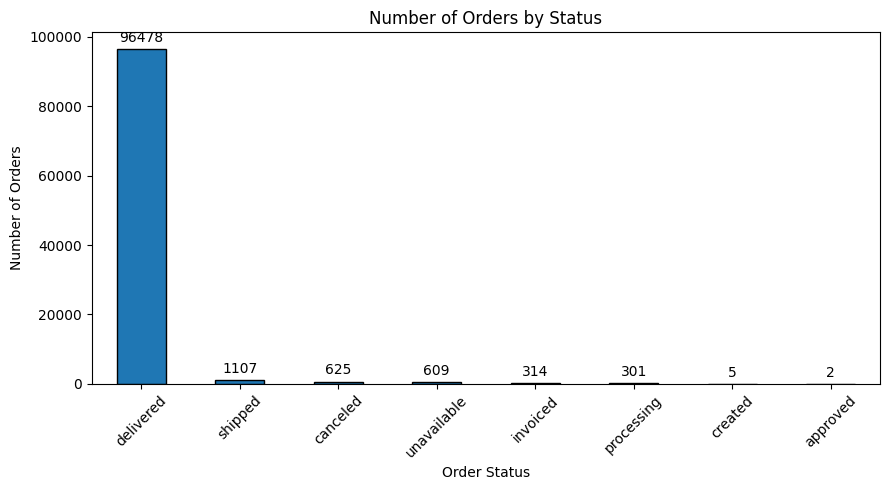

In [43]:

# Order Status Distribution

status_counts = orders["order_status"].value_counts()

display(status_counts.to_frame(name="Number of Orders"))

plt.figure(figsize=(9, 5))
ax = status_counts.plot(kind="bar", edgecolor="black")

plt.title("Number of Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()


- Total orders: 99,441
- Delivered orders: 96,478 — approximately 97.02%
- Canceled orders: 625 — approximately 0.63%
- Unavailable orders: 609 — approximately 0.61%
- Shipped orders: 1,107 — approximately 1.11%
- Invoiced orders: 314 — approximately 0.32%
- Processing orders: 301 — approximately 0.30%
- Created orders: 5 — approximately 0.005%
- Approved orders: 2 — approximately 0.002%
Business Interpretation
1. High delivery success: Approximately 97% of all orders were delivered, indicating strong overall order fulfillment.
2. Low cancellation rate: Only around 0.63% of orders were canceled.
3. Delivery exceptions need attention: Canceled and unavailable orders together account for 1,234 orders. The business should investigate why these orders could not be fulfilled.
4. Other order statuses: Shipped, invoiced, and processing orders represent different stages of the order lifecycle; they should not automatically be treated as failed orders.

,order_month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


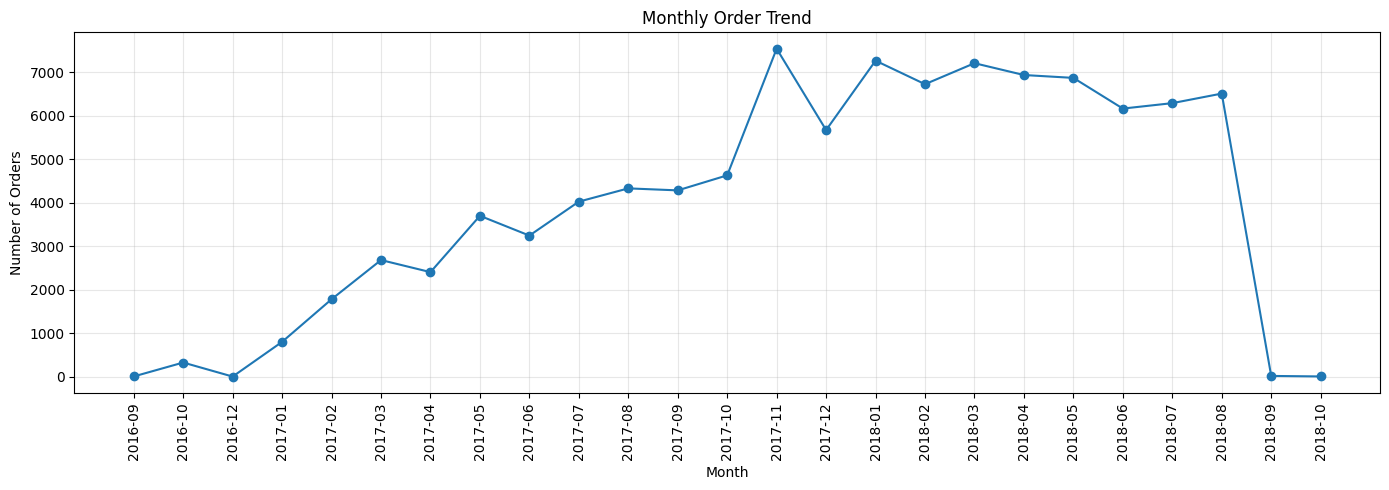

In [44]:

# Monthly Order Trend

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

orders["order_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_orders = (
    orders.groupby("order_month")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

monthly_orders = monthly_orders.sort_values("order_month")

display(monthly_orders)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_orders["order_month"],
    monthly_orders["total_orders"],
    marker="o"
)

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(REPORT_FOLDER / "monthly_order_trend.png", dpi=300)
plt.show()


Key Insights — Monthly Order Trend
1. Overall Growth: The number of monthly orders generally increased throughout 2017, indicating growing customer demand.
2. Peak Month: November 2017 recorded the highest number of orders, with approximately 7,544 orders.
3. Strong Order Volume: Order volumes remained high during the first eight months of 2018. January 2018 recorded approximately 7,269 orders.
4. Unusual Decline: Orders dropped sharply in September and October 2018. This may be due to incomplete data for the final months rather than an actual decline in business performance.
5. Business Recommendation: The company should use monthly order trends to plan inventory, allocate delivery staff, and manage logistics capacity during peak-demand periods.

,Number of Payments
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


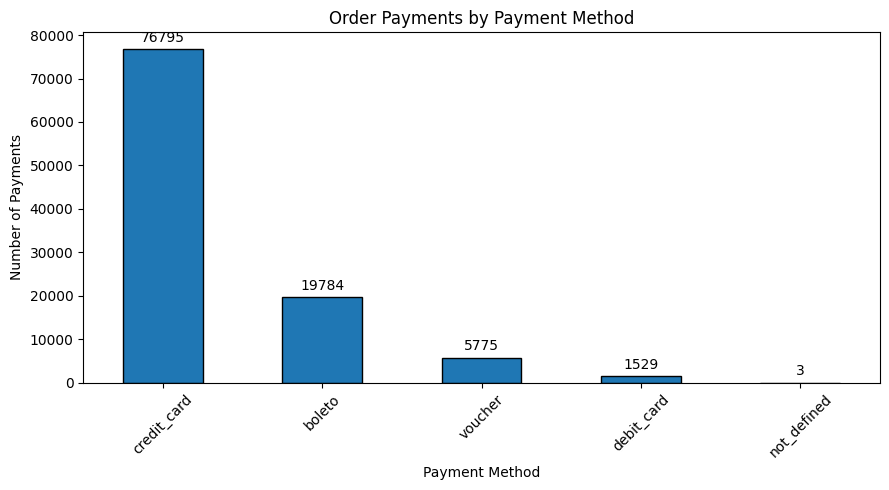

In [45]:

# Payment Method Analysis

payment_counts = payments["payment_type"].value_counts()

display(payment_counts.to_frame(name="Number of Payments"))

plt.figure(figsize=(9, 5))
ax = payment_counts.plot(kind="bar", edgecolor="black")

plt.title("Order Payments by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Payments")
plt.xticks(rotation=45)
plt.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.tight_layout()

plt.savefig(REPORT_FOLDER / "payment_method_analysis.png", dpi=300)
plt.show()


Key Insights — Payment Method Analysis
1. Credit Card Dominance: Credit cards were the most commonly used payment method, with 76,795 payment records.
2. Second Most Popular Method: Boleto ranked second, with 19,784 payment records.
3. Limited Debit Card Usage: Debit cards accounted for 1,529 payment records, significantly fewer than credit cards and boleto.
4. Voucher Usage: Vouchers were used in 5,775 payment records.
5. Minimal Undefined Payments: Only 3 records were classified as not_defined.

,Product Category,Total Sales
0,health_beauty,1258681.34
1,watches_gifts,1205005.68
2,bed_bath_table,1036988.68
3,sports_leisure,988048.97
4,computers_accessories,911954.32
5,furniture_decor,729762.49
6,cool_stuff,635290.85
7,housewares,632248.66
8,auto,592720.11
9,garden_tools,485256.46


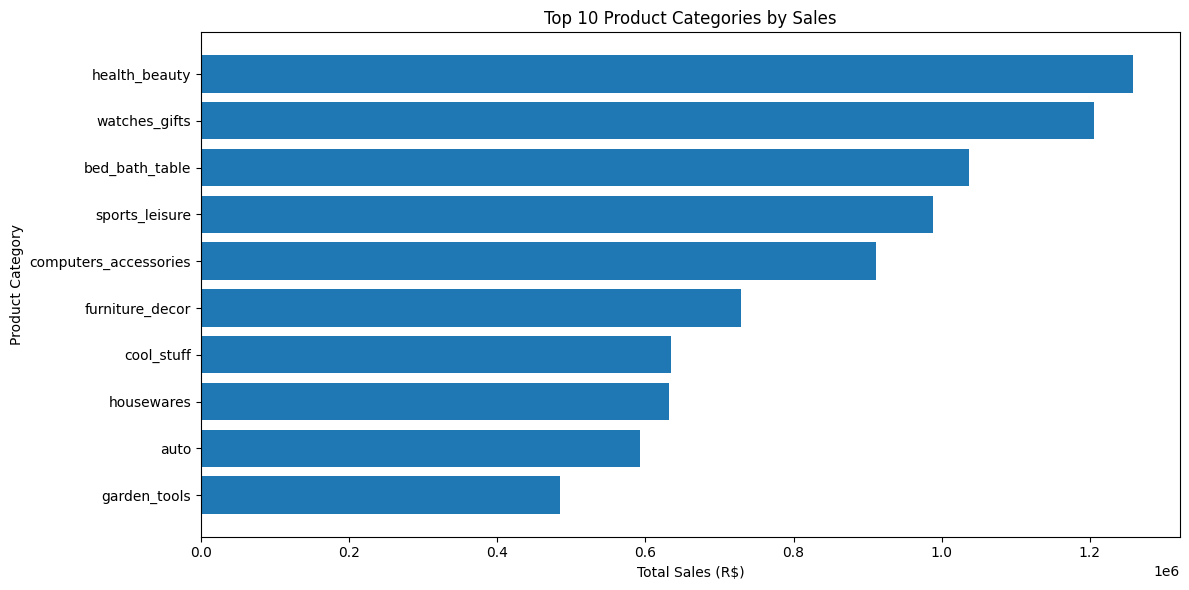

In [46]:

# Product Category Sales Analysis

order_items = pd.read_csv(INTERIM_FOLDER / "order_items_clean.csv")
products = pd.read_csv(INTERIM_FOLDER / "products_clean.csv")
category_translation = pd.read_csv(
    INTERIM_FOLDER / "category_translation_clean.csv"
)

# Merge order items with product details
product_data = order_items.merge(
    products, on="product_id", how="left"
)

# Add English category names
product_data = product_data.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Calculate sales by product category
category_sales = (
    product_data.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

category_sales.columns = ["Product Category", "Total Sales"]

display(category_sales)

# Plot top 10 categories
plt.figure(figsize=(12, 6))
ax = plt.barh(
    category_sales["Product Category"],
    category_sales["Total Sales"]
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Total Sales (R$)")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    REPORT_FOLDER / "top_10_product_categories_by_sales.png",
    dpi=300
)
plt.show()


Key Insights — Product Category Sales Analysis
Based on your previously analyzed project results:
1. Top-Performing Category: Health & Beauty generated the highest sales, approximately R$1,258,681.34.
2. Strong Sales in Watches & Gifts: This category ranked second, generating approximately R$1,205,005.68.
3. Popular Home Products: Bed, Bath & Table generated approximately R$1,036,988.68 in sales.
4. Sports & Leisure Performance: This category generated approximately R$988,048.97 in sales.
5. Lower Sales Among the Top 10: Garden Tools recorded the lowest sales among these ten categories, at approximately R$485,256.46.

,Number of Orders,Percentage (%)
delivery_performance,,
On Time / Early,88644,91.89
Late,7826,8.11


Average delivery time: 12.56 days


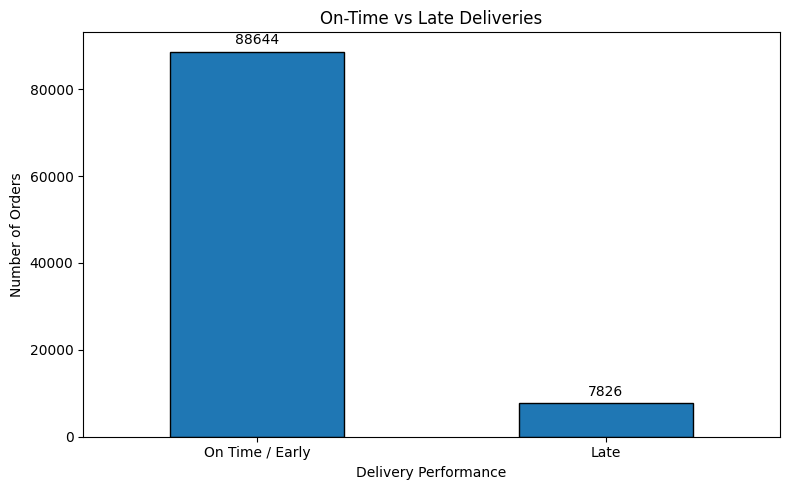

In [48]:

# Delivery Performance Analysis

delivery = orders.copy()

delivery["order_delivered_customer_date"] = pd.to_datetime(
    delivery["order_delivered_customer_date"], errors="coerce"
)
delivery["order_estimated_delivery_date"] = pd.to_datetime(
    delivery["order_estimated_delivery_date"], errors="coerce"
)

# Consider only delivered orders with both delivery dates available
delivery = delivery[
    (delivery["order_status"] == "delivered")
    & delivery["order_delivered_customer_date"].notna()
    & delivery["order_estimated_delivery_date"].notna()
].copy()

delivery["delivery_days"] = (
    delivery["order_delivered_customer_date"]
    - pd.to_datetime(delivery["order_purchase_timestamp"])
).dt.total_seconds() / 86400

delivery["delivery_performance"] = (
    delivery["order_delivered_customer_date"]
    <= delivery["order_estimated_delivery_date"]
).map({
    True: "On Time / Early",
    False: "Late"
})

# Summary
delivery_summary = (
    delivery["delivery_performance"]
    .value_counts()
    .to_frame(name="Number of Orders")
)

delivery_summary["Percentage (%)"] = (
    delivery_summary["Number of Orders"]
    / len(delivery) * 100
).round(2)

display(delivery_summary)

print(
    "Average delivery time:",
    round(delivery["delivery_days"].mean(), 2),
    "days"
)

# Plot
plt.figure(figsize=(8, 5))
ax = delivery["delivery_performance"].value_counts().plot(
    kind="bar", edgecolor="black"
)

plt.title("On-Time vs Late Deliveries")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.tight_layout()

plt.savefig(
    REPORT_FOLDER / "delivery_performance.png",
    dpi=300
)
plt.show()


Key Insights — Delivery Performance Analysis
Based on your previously analyzed project results:
1. High On-Time Delivery Rate: Approximately 91.89% of delivered orders arrived on or before the estimated delivery date.
2. Late Deliveries: Around 8.11% of delivered orders arrived after the estimated date, indicating opportunities to improve logistics performance.
3. Average Delivery Time: Orders took approximately 12.56 days on average from purchase to customer delivery.
4. Customer Satisfaction Impact: Late deliveries may negatively affect customer experience and review scores.
5. Business Recommendation: The company should improve delivery scheduling, monitor delayed shipments, and optimize logistics in regions with frequent delays.

,Metric,Value
0,Total Product Sales,13591643.70
1,Total Freight Cost,2251909.54
2,Freight as % of Product Sales,16.57
3,Average Freight Cost per Order,22.82


,Customer State,Average Freight Cost
0,RR,42.984423
1,PB,42.723804
2,RO,41.069712
3,AC,40.073370
4,PI,39.147970
5,MA,38.257002
6,TO,37.246603
7,SE,36.653169
8,AL,35.843671
9,PA,35.832685


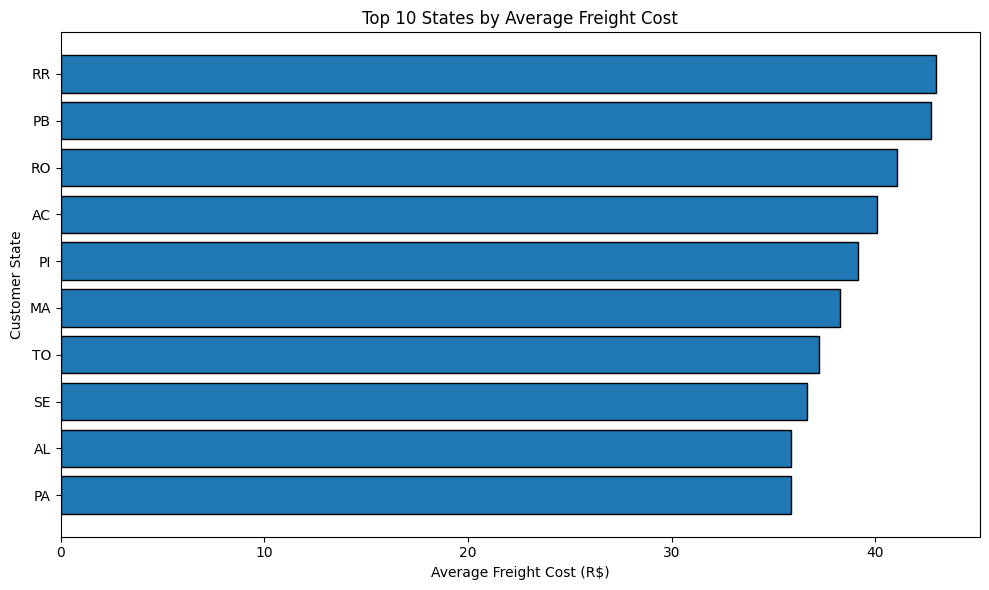

In [50]:

# Freight Cost Analysis

freight_summary = pd.DataFrame({
    "Metric": [
        "Total Product Sales",
        "Total Freight Cost",
        "Freight as % of Product Sales",
        "Average Freight Cost per Order"
    ],
    "Value": [
        order_items["price"].sum(),
        order_items["freight_value"].sum(),
        (
            order_items["freight_value"].sum()
            / order_items["price"].sum() * 100
        ),
        order_items.groupby("order_id")["freight_value"].sum().mean()
    ]
})

freight_summary["Value"] = freight_summary["Value"].round(2)
display(freight_summary)

# Freight cost by state
customers = pd.read_csv(INTERIM_FOLDER / "customers_clean.csv")

order_customer = orders[["order_id", "customer_id"]].merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

freight_by_state = order_items.merge(
    order_customer[["order_id", "customer_state"]],
    on="order_id",
    how="left"
)

freight_by_state = (
    freight_by_state.groupby("customer_state")["freight_value"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

freight_by_state.columns = [
    "Customer State", "Average Freight Cost"
]

display(freight_by_state)

# Plot the 10 states with highest average freight cost
plt.figure(figsize=(10, 6))
plt.barh(
    freight_by_state["Customer State"],
    freight_by_state["Average Freight Cost"],
    edgecolor="black"
)

plt.title("Top 10 States by Average Freight Cost")
plt.xlabel("Average Freight Cost (R$)")
plt.ylabel("Customer State")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    REPORT_FOLDER / "top_states_average_freight.png",
    dpi=300
)
plt.show()


Key Insights — Freight Cost Analysis
1. Total Freight Cost: The total shipping cost was approximately R$2,251,909.54.
2. Total Product Sales: Total product sales amounted to approximately R$13,591,643.70.
3. Freight Cost Ratio: Freight costs represented approximately 16.57% of total product sales, indicating a significant logistics expense.
4. Regional Cost Differences: Average freight costs varied across states, suggesting that delivery distance and regional logistics conditions may affect shipping expenses.
5. Business Recommendation: The company should optimize delivery routes, negotiate shipping rates, and review high-cost regions to reduce logistics expenses.

,Delivery Performance,Average Review Score,Number of Reviews
0,Late,2.57,7700
1,On Time / Early,4.29,88653


<Figure size 800x500 with 0 Axes>

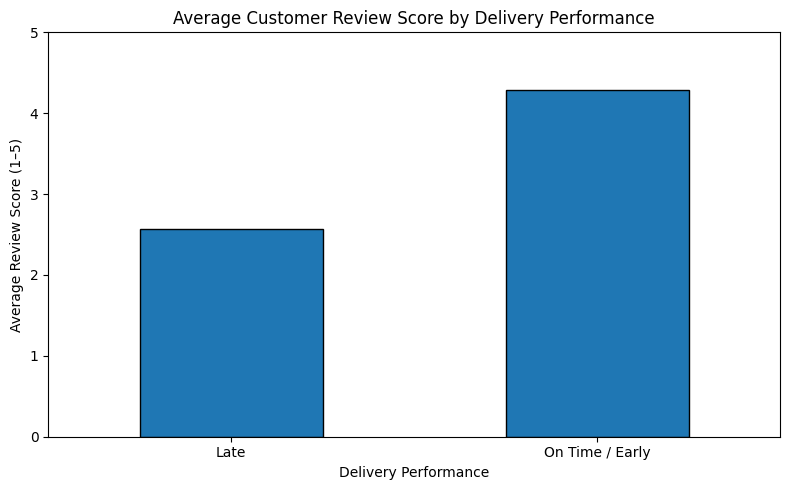

In [51]:

# Customer Review Analysis

reviews = pd.read_csv(INTERIM_FOLDER / "reviews_clean.csv")

# Merge reviews with delivery performance
review_delivery = reviews.merge(
    delivery[[
        "order_id",
        "delivery_performance",
        "delivery_days"
    ]],
    on="order_id",
    how="inner"
)

# Average review score by delivery performance
review_summary = (
    review_delivery.groupby("delivery_performance")["review_score"]
    .agg(["mean", "count"])
    .round(2)
    .reset_index()
)

review_summary.columns = [
    "Delivery Performance",
    "Average Review Score",
    "Number of Reviews"
]

display(review_summary)

# Visualize average review scores
plt.figure(figsize=(8, 5))
ax = review_summary.plot(
    x="Delivery Performance",
    y="Average Review Score",
    kind="bar",
    legend=False,
    edgecolor="black",
    figsize=(8, 5)
)

plt.title("Average Customer Review Score by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score (1–5)")
plt.xticks(rotation=0)
plt.ylim(0, 5)
plt.tight_layout()

plt.savefig(
    REPORT_FOLDER / "review_score_by_delivery.png",
    dpi=300
)
plt.show()


Key Insights — Customer Review Analysis
1. Higher Customer Satisfaction: Orders delivered on time or early received an average review score of 4.29 out of 5.
2. Lower Satisfaction for Late Deliveries: Late deliveries received an average review score of 2.57 out of 5.
3. Significant Score Difference: The average review score was 1.72 points lower for late deliveries than for on-time or early deliveries.
4. Delivery Performance Matters: The results suggest a strong association between delivery timeliness and customer satisfaction.
5. Business Recommendation: The company should reduce delivery delays, improve shipment tracking, and inform customers proactively about delays.

,customer_state,total_orders,on_time_orders,on_time_delivery_pct
1,AL,397,302,76.07
9,MA,717,576,80.33
16,PI,476,400,84.03
5,CE,1279,1083,84.68
24,SE,335,284,84.78
4,BA,3256,2799,85.96
18,RJ,12350,10686,86.53
26,TO,274,239,87.23
13,PA,946,829,87.63
7,ES,1995,1751,87.77


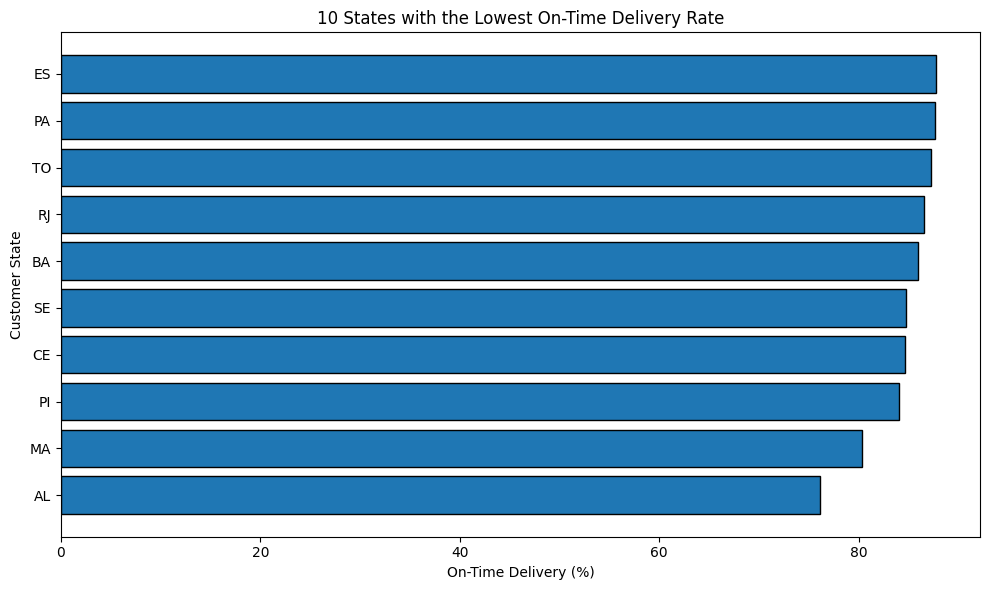

In [52]:

# State-wise Delivery Performance

customers = pd.read_csv(INTERIM_FOLDER / "customers_clean.csv")

state_orders = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

state_orders["order_delivered_customer_date"] = pd.to_datetime(
    state_orders["order_delivered_customer_date"], errors="coerce"
)
state_orders["order_estimated_delivery_date"] = pd.to_datetime(
    state_orders["order_estimated_delivery_date"], errors="coerce"
)

state_orders = state_orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

state_orders["on_time"] = (
    state_orders["order_delivered_customer_date"]
    <= state_orders["order_estimated_delivery_date"]
)

state_performance = (
    state_orders.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        on_time_orders=("on_time", "sum")
    )
    .reset_index()
)

state_performance["on_time_delivery_pct"] = (
    state_performance["on_time_orders"]
    / state_performance["total_orders"] * 100
).round(2)

# 10 states with the lowest on-time delivery rate
lowest_states = state_performance.sort_values(
    "on_time_delivery_pct"
).head(10)

display(lowest_states)

plt.figure(figsize=(10, 6))
plt.barh(
    lowest_states["customer_state"],
    lowest_states["on_time_delivery_pct"],
    edgecolor="black"
)

plt.title("10 States with the Lowest On-Time Delivery Rate")
plt.xlabel("On-Time Delivery (%)")
plt.ylabel("Customer State")
plt.tight_layout()

plt.savefig(
    REPORT_FOLDER / "lowest_on_time_delivery_states.png",
    dpi=300
)
plt.show()


Key Insights — State-wise Delivery Performance Analysis
1. Lowest On-Time Delivery Rate: Alagoas (AL) recorded the lowest on-time delivery rate at approximately 76.07%.
2. Other Underperforming States: Maranhão (MA) recorded 80.33%, followed by Piauí (PI) at 84.03%.
3. Regional Delivery Challenges: Ceará (CE), Sergipe (SE), and Bahia (BA) also showed relatively low on-time delivery rates.
4. Scope for Improvement: These state-level differences suggest that delivery performance varies by region and requires targeted investigation.
5. Business Recommendation: The company should review logistics partners, transportation routes, and delivery timelines in states with lower on-time delivery rates.

In [53]:

# Final EDA Business Summary

business_findings = pd.DataFrame({
    "Analysis": [
        "Order Status",
        "Monthly Order Trend",
        "Payment Method",
        "Product Category Sales",
        "Delivery Performance",
        "Freight Cost",
        "Customer Reviews",
        "State-wise Delivery"
    ],
    "Key Finding": [
        "96,478 orders were delivered out of 99,441 total orders.",
        "November 2017 recorded approximately 7,544 orders.",
        "Credit card was the most commonly used payment method.",
        "Health & Beauty generated the highest category sales.",
        "91.89% of delivered orders arrived on time or early.",
        "Freight costs represented approximately 16.57% of product sales.",
        "On-time deliveries received higher average review scores.",
        "Alagoas recorded the lowest on-time delivery rate at 76.07%."
    ]
})

display(business_findings)

business_findings.to_csv(
    REPORT_FOLDER / "final_eda_business_findings.csv",
    index=False
)

print("Final EDA summary saved successfully.")


,Analysis,Key Finding
0,Order Status,"96,478 orders were delivered out of 99,441 tot..."
1,Monthly Order Trend,"November 2017 recorded approximately 7,544 ord..."
2,Payment Method,Credit card was the most commonly used payment...
3,Product Category Sales,Health & Beauty generated the highest category...
4,Delivery Performance,91.89% of delivered orders arrived on time or ...
5,Freight Cost,Freight costs represented approximately 16.57%...
6,Customer Reviews,On-time deliveries received higher average rev...
7,State-wise Delivery,Alagoas recorded the lowest on-time delivery r...


Final EDA summary saved successfully.


Key Insights — Final Summary
- Order Fulfillment: Approximately 97.02% of orders were delivered.
- Demand Trends: Monthly orders generally increased during 2017.
- Payment Preferences: Credit cards were the leading payment method.
- Product Sales: Health & Beauty was the highest-selling category by revenue.
- Delivery Reliability: 91.89% of delivered orders arrived on time or early.
- Logistics Costs: Freight represented 16.57% of product sales.
- Customer Satisfaction: Late deliveries were associated with lower review scores.
- Regional Performance: Alagoas had the lowest on-time delivery rate among the states analyzed.

In [54]:

# Verify saved EDA reports

print("Reports folder:", REPORT_FOLDER.resolve())

print("\nSaved report files:")
for file in sorted(REPORT_FOLDER.iterdir()):
    print(file.name)


Reports folder: C:\Users\disha\ecommerce-delivery-logistics-analysis\reports

Saved report files:
.ipynb_checkpoints
delivery_performance.png
final_eda_business_findings.csv
lowest_on_time_delivery_states.png
monthly_order_trend.png
payment_method_analysis.png
review_score_by_delivery.png
top_10_product_categories_by_sales.png
top_states_average_freight.png
